## **Load the Dataset**

In [1]:
from google.colab import files

# Upload the Dataset
uploaded = files.upload()

Saving stock_details_5_years.csv to stock_details_5_years.csv


In [2]:
import pandas as pd

# Load the dataset
df = pd.read_csv("stock_details_5_years.csv")

## **Initial - Exploratory Data Analysis (EDA)**

In [3]:
# Print the first 5 rows of the dataset
df.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits,Company
0,2018-11-29 00:00:00-05:00,43.829761,43.863354,42.639594,43.083508,167080000,0.00,0.0,AAPL
1,2018-11-29 00:00:00-05:00,104.769074,105.519257,103.534595,104.636131,28123200,0.00,0.0,MSFT
2,2018-11-29 00:00:00-05:00,54.176498,55.007500,54.099998,54.729000,31004000,0.00,0.0,GOOGL
3,2018-11-29 00:00:00-05:00,83.749496,84.499496,82.616501,83.678497,132264000,0.00,0.0,AMZN
4,2018-11-29 00:00:00-05:00,39.692784,40.064904,38.735195,39.037853,54917200,0.04,0.0,NVDA


In [4]:
# Get information about each Datatype of the column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 602962 entries, 0 to 602961
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Date          602962 non-null  object 
 1   Open          602962 non-null  float64
 2   High          602962 non-null  float64
 3   Low           602962 non-null  float64
 4   Close         602962 non-null  float64
 5   Volume        602962 non-null  int64  
 6   Dividends     602962 non-null  float64
 7   Stock Splits  602962 non-null  float64
 8   Company       602962 non-null  object 
dtypes: float64(6), int64(1), object(2)
memory usage: 41.4+ MB


In [5]:
# Get the shape of the dataset
df.shape

(602962, 9)

## **Data Preprocessing**

In [6]:
# Set Date datatype object to Date

df.Date = pd.to_datetime(df.Date, utc=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 602962 entries, 0 to 602961
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype              
---  ------        --------------   -----              
 0   Date          602962 non-null  datetime64[ns, UTC]
 1   Open          602962 non-null  float64            
 2   High          602962 non-null  float64            
 3   Low           602962 non-null  float64            
 4   Close         602962 non-null  float64            
 5   Volume        602962 non-null  int64              
 6   Dividends     602962 non-null  float64            
 7   Stock Splits  602962 non-null  float64            
 8   Company       602962 non-null  object             
dtypes: datetime64[ns, UTC](1), float64(6), int64(1), object(1)
memory usage: 41.4+ MB


In [7]:
# Check missing values
df.isnull().sum()


,0
Date,0
Open,0
High,0
Low,0
Close,0
Volume,0
Dividends,0
Stock Splits,0
Company,0


In [8]:
# Check for duplicated values
df.duplicated().sum()

np.int64(0)

In [9]:
# Sort the dataset by Company and Date
df = df.sort_values(["Company", "Date"])

## **Exploratory Data Analysis (EDA)**

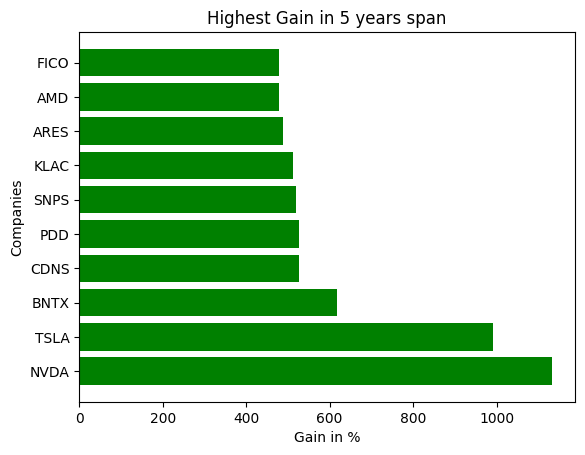

In [10]:
# Top 10 Companies with the highest Gain in 5 years span

import matplotlib.pyplot as plt
import seaborn as sns

first_close = df.groupby("Company")["Close"].first()
last_close = df.groupby("Company")["Close"].last()

# Calculate the gain in full time span
total_return = (last_close / first_close - 1) * 100

top_10_gainers = total_return.sort_values(ascending=False).head(10)

gainers_companies = top_10_gainers.index
gainers_gain = top_10_gainers.values

plt.barh(gainers_companies, gainers_gain, color="green")
plt.title("Highest Gain in 5 years span")
plt.xlabel("Gain in %")
plt.ylabel("Companies")
plt.show()


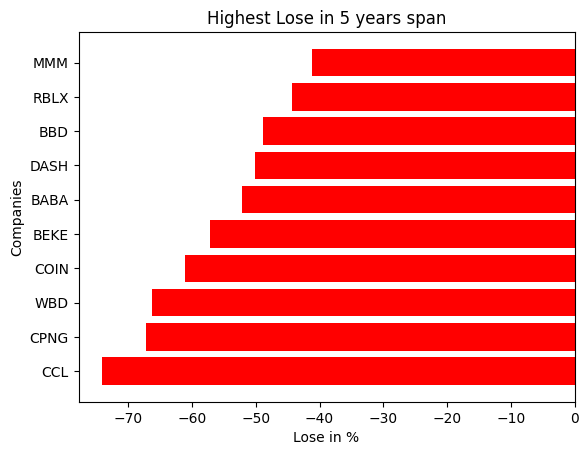

In [11]:
# Top 10 Comanies with the highest Lose in 5 years span

top_10_lossers = total_return.sort_values(ascending=True).head(10)

lossers_companies = top_10_lossers.index
lossers_gain = top_10_lossers.values

plt.barh(lossers_companies, lossers_gain, color="red")
plt.title("Highest Lose in 5 years span")
plt.xlabel("Lose in %")
plt.ylabel("Companies")
plt.show()

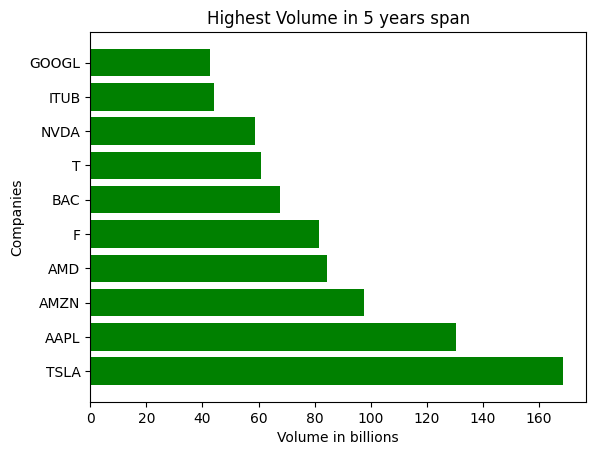

In [12]:
# Top 10 Companies with the highest Volume in 5 years span

# Sums the volume over the full time span
sum_volume = df.groupby("Company")["Volume"].sum()

top10_volume = sum_volume.sort_values(ascending=False).head(10)

companies = top10_volume.index

# Scale the volumes to billions
volumes = top10_volume.values / 1000000000

plt.barh(companies, volumes, color="green")
plt.title("Highest Volume in 5 years span")
plt.xlabel("Volume in billions")
plt.ylabel("Companies")
plt.show()


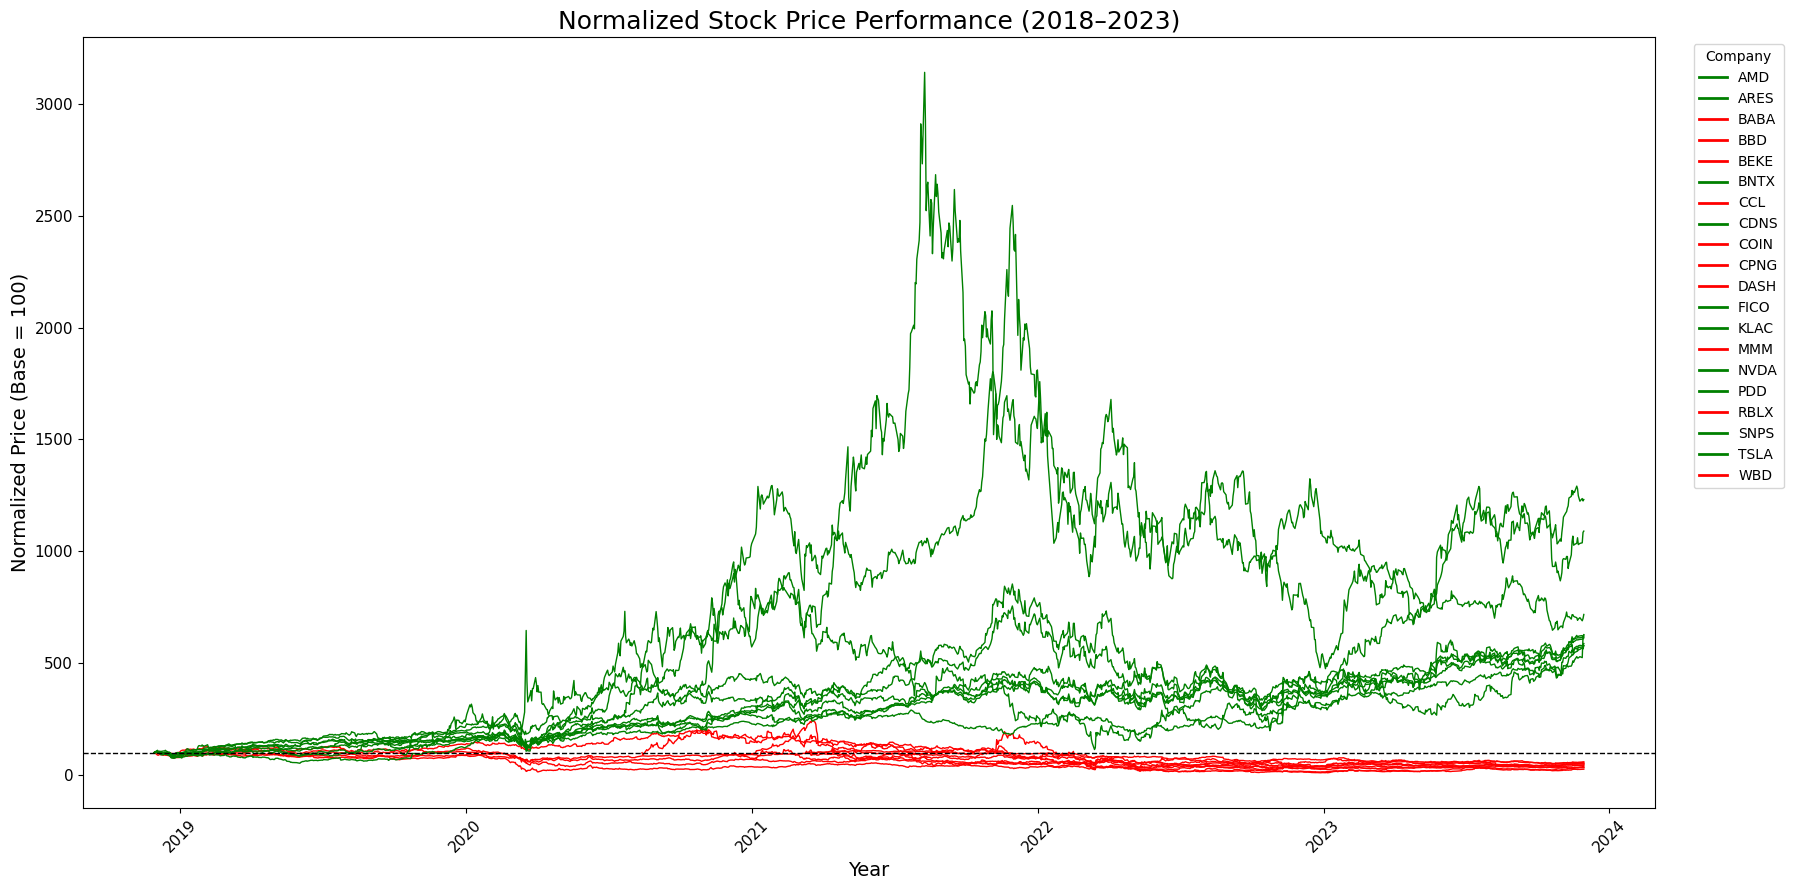

In [17]:
# Visualization of the top 10 companies with the highest gain and the highest lose, how the stock prices has developed over the years

from matplotlib.lines import Line2D

stock_prices = df[["Date", "Company", "Normalized_Price"]]


gainer_stocks = stock_prices[stock_prices["Company"].isin(gainers_companies.tolist())]
losser_stocks = stock_prices[stock_prices["Company"].isin(lossers_companies.tolist())]

plt.figure(figsize=(18, 9))

sns.lineplot(
    data=losser_stocks,
    x="Date",
    y="Normalized_Price",
    units="Company",
    estimator=None,
    linewidth=1,
    color="red"
)

sns.lineplot(
    data=gainer_stocks,
    x="Date",
    y="Normalized_Price",
    units="Company",
    estimator=None,
    linewidth=1,
    color="green"
)

plt.title("Normalized Stock Price Performance (2018–2023)", fontsize=18)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Normalized Price (Base = 100)", fontsize=14)
plt.axhline(y=100, color="black", linestyle="--", linewidth=1)

companies = sorted(
    set(losser_stocks["Company"]) |
    set(gainer_stocks["Company"])
)

legend_handles = []

for company in companies:
    color = (
        "red"
        if company in set(losser_stocks["Company"])
        else "green"
    )

    legend_handles.append(
        Line2D([0], [0], color=color, linewidth=2, label=company)
    )

plt.legend(
    handles=legend_handles,
    title="Company",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    fontsize=10
)

plt.xticks(fontsize=11, rotation=45)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

## **Feature Engineering**

In [13]:
# Normalized Price shows how the stock price has developed over the years relative to its starting price (base = 100)
df["Normalized_Price"] = (df["Close"] / df["Company"].map(first_close)) * 100

In [14]:
# Daily Return shows the percentage change in the value of an stock, from the one day to the other
df["Daily_Return"] = (df.groupby("Company")["Close"].pct_change() * 100)

In [15]:
# Rolling Volatility shows how much an assets price swings over the past 30 trading days in this Case
df["Rolling_Volatility"] = (df.groupby("Company")["Daily_Return"].transform(lambda x: x.rolling(30).std() * 100))

In [16]:
# New shape of the dataset
df.shape

(602962, 12)

## **Time Series Forecasting (ARIMA)**

#### **ARIMA for all Stocks**

In [162]:
import numpy as np
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Initialize lists to store evaluation metrics and predictions for all stocks
all_results = []
all_predictions = []

# Iterate over each stock
for company, data in df.groupby("Company"):
    data = data.sort_values("Date")

    # Extract closing prices and dates
    close = data["Close"].to_numpy()
    dates = data["Date"].to_numpy()

    # Determine the number of observations and split the data
    n = len(close)
    train_size = int(n * 0.8)

    # Create training and test sets
    train = close[:train_size]
    test = close[train_size:]
    test_dates = data["Date"].iloc[train_size:]

    # Skip stocks with insufficient training or test data
    if len(train) < 3 or len(test) == 0:
      continue

    # Calculate the average absolute change in the training data for MASE
    naive_train_mae = np.mean(np.abs(np.diff(train)))

    # Skip stocks with no variation in training prices
    if naive_train_mae == 0:
      continue



    # Initialize the forecasting history and prediction lists
    history = list(train)
    arima_predictions = []

    # Generate baseline predictions using the previous actual closing price
    baseline_predictions = np.concatenate(([train[-1]], test[:-1]))

    # Perform rolling one-step-ahead forecasts
    for actual in test:

        # Fit the ARIMA model using the available historical data
        model = ARIMA(history, order=(1, 1, 0))
        fitted_model = model.fit()

        # Forecast the next closing price
        prediction = fitted_model.forecast(steps=1)[0]
        arima_predictions.append(prediction)

        # Add the actual closing price to the history for the next forecast
        history.append(actual)

    # Convert predictions to a NumPy array for metric calculations
    arima_predictions = np.array(arima_predictions)

    # Calculate ARIMA evaluation metrics
    arima_mae = mean_absolute_error(test, arima_predictions)
    arima_rmse = np.sqrt(mean_squared_error(test, arima_predictions))
    arima_mape = np.mean(np.abs((test - np.array(arima_predictions)) / test)) * 100

    # Calculate baseline evaluation metrics
    baseline_mae = mean_absolute_error(test, baseline_predictions)
    baseline_rmse = np.sqrt(mean_squared_error(test, baseline_predictions))

    # Calculate the Mean Absolute Scaled Error (MASE)
    mase = arima_mae / naive_train_mae

    # Store the evaluation metrics for the current stock
    all_results.append({
        "Company": company,
        "ARIMA_MAE": arima_mae,
        "Baseline_MAE": baseline_mae,
        "ARIMA_RMSE": arima_rmse,
        "Baseline_RMSE": baseline_rmse,
        "ARIMA_MAPE": arima_mape,
        "MASE": mase,
        "ARIMA_beats_Baseline": arima_mae < baseline_mae
    })

    # Store actual and predicted closing prices for the current stock
    all_predictions.append(pd.DataFrame({
        "Company": company,
        "Date": test_dates,
        "Actual_Close": test,
        "ARIMA_Predicted": arima_predictions,
        "Baseline_Predicted": baseline_predictions
    }))


    # Combine the evaluation metrics for all stocks into one DataFrame
    metrics_allstocks_df = pd.DataFrame(all_results)

    # Combine the predictions for all stocks into one DataFrame
    predictions_allstocks_df = pd.concat(all_predictions, ignore_index=True)




/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local

#### **META Case Study - Model Development**

##### **1. META Stock Data Overview**

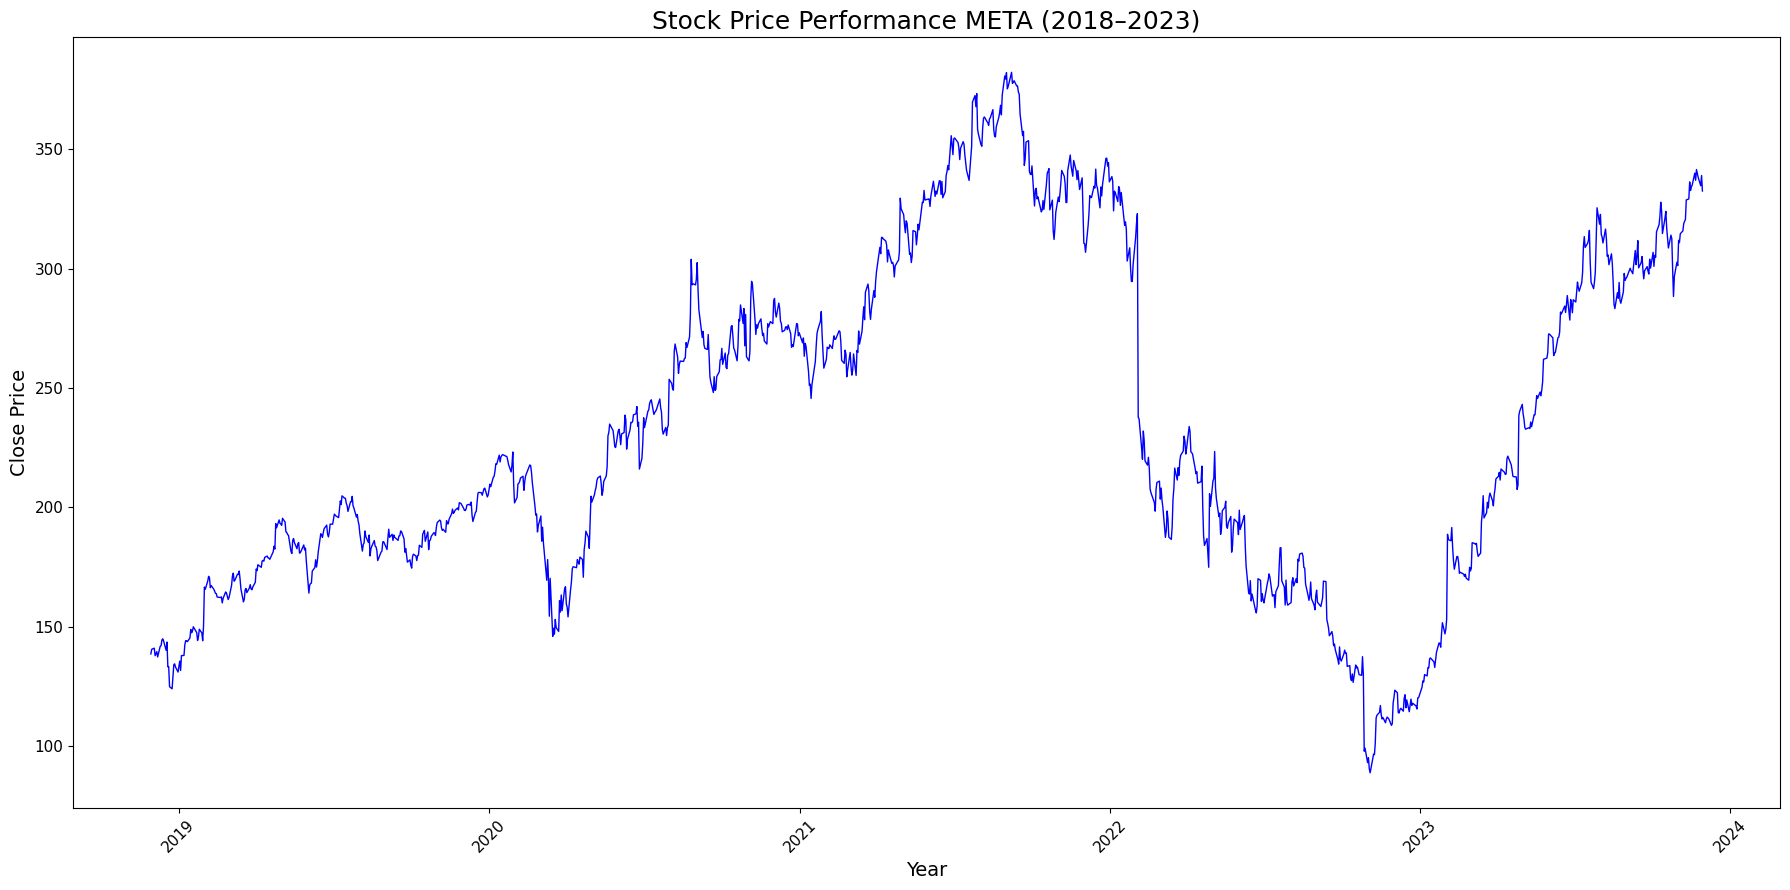

In [163]:
# META stock price development

plt.figure(figsize=(18, 9))

sns.lineplot(
    data=df[df["Company"] == "META"],
    x="Date",
    y="Close",
    linewidth=1,
    color="blue"
)


plt.title("Stock Price Performance META (2018–2023)", fontsize=18)
plt.xlabel("Year", fontsize=14)
plt.ylabel("Close Price", fontsize=14)
plt.xticks(fontsize=11, rotation=45)
plt.yticks(fontsize=11)
plt.tight_layout()
plt.show()

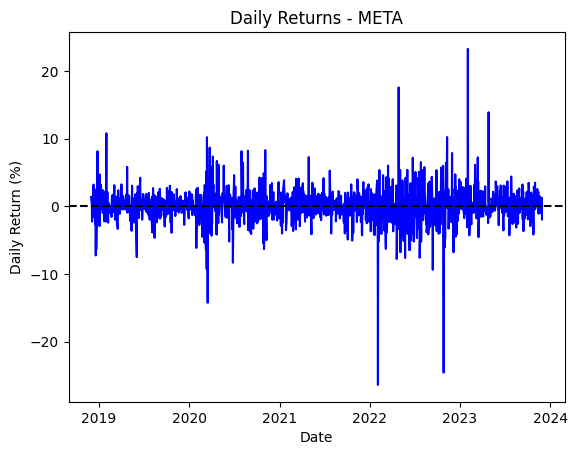

In [164]:
# META Daily Returns

sns.lineplot(
    data=df[df["Company"] == "META"],
    x="Date",
    y="Daily_Return",
    color="blue"
)

plt.axhline(0, color="black", linestyle="--")
plt.title("Daily Returns - META")
plt.ylabel("Daily Return (%)")
plt.show()

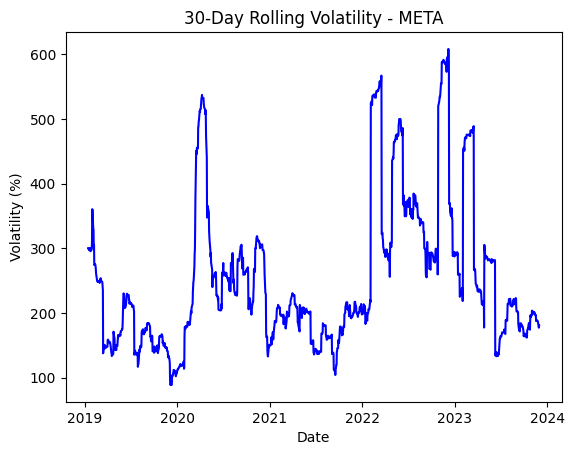

In [165]:
# META 30-day rolling volatility

sns.lineplot(
    data=df[df["Company"] == "META"],
    x="Date",
    y="Rolling_Volatility",
    color="blue"
)

plt.title("30-Day Rolling Volatility - META")
plt.ylabel("Volatility (%)")
plt.show()

##### **2. ARIMA Parameter Selection**

In [166]:
from statsmodels.tsa.stattools import adfuller

# Augmented Dickey-Fuller (ADF) Test for stationary

meta_closes = (df[df["Company"] == "META"].sort_values("Date")["Close"])

# Perform the ADF test on the original series and after each differencing step
for d in range(3):
    result = adfuller(meta_closes)

    # Print the current differencing order
    print(f"d = {d}")
    print(f"ADF statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.6f}")

    # Apply first-order differencing to help achieve stationarity
    meta_closes = meta_closes.diff().dropna()

d = 0
ADF statistic: -1.3967
p-value: 0.583860
d = 1
ADF statistic: -21.6302
p-value: 0.000000
d = 2
ADF statistic: -14.7788
p-value: 0.000000


/tmp/ipykernel_991/339111653.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(meta_closes)
/tmp/ipykernel_991/339111653.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(meta_closes)
/tmp/ipykernel_991/339111653.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In

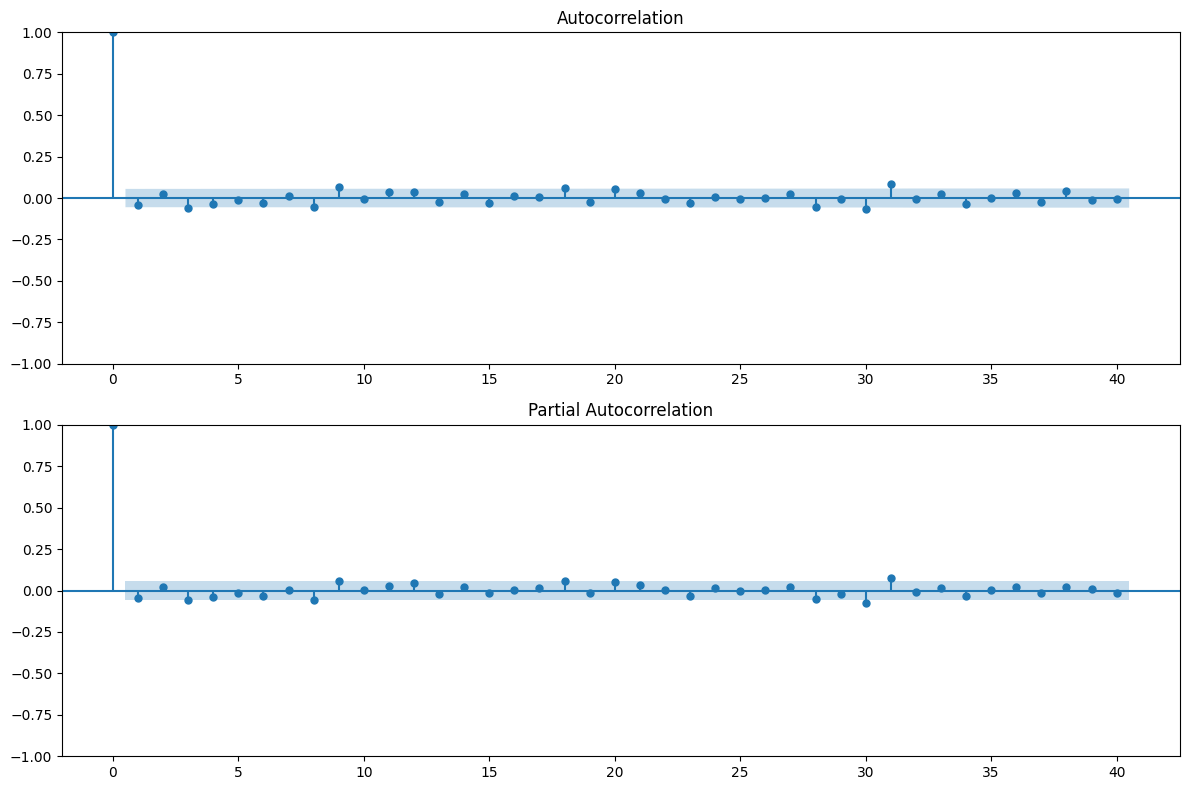

In [167]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# ACF and PACF Analysis for META's Differenced Closing Prices

meta = (df[df["Company"] == "META"].sort_values("Date")["Close"])

# Apply first-order differencing to the closing prices
meta_diff = meta.diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

# Plot the autocorrelation function (ACF)
plot_acf(meta_diff, lags=40, ax=axes[0])

# Plot the partial autocorrelation function (PACF)
plot_pacf(meta_diff, lags=40, method="ywm", ax=axes[1])

plt.tight_layout()
plt.show()

##### **Conclusion from ACF and PACF Analysis**

Based on the ACF and PACF plots of the first-differenced closing-price series, ARIMA(0, 1, 1) was selected as a candidate model. First-order differencing ((d=1)) was applied to address the non-stationarity of the original price series. The choice of (p=0) and (q=1) was guided by the autocorrelation patterns observed in the plots. However, ACF and PACF plots alone do not guarantee that this is the optimal model order. Therefore, the model's forecasting performance was evaluated and compared with a naive baseline.

##### **3. Train the Model**

In [169]:
# Select META's stock data
meta = df[df["Company"] == "META"].sort_values("Date")
meta_closes = meta["Close"].to_numpy()

# Determine the number of observations
n = len(meta_closes)

# Split the data into training and test sets
train = meta_closes[:train_size]
test = meta_closes[train_size:]

# Extract the dates corresponding to the test set
test_dates = meta["Date"].iloc[train_size:].to_numpy()

# Initialize the forecasting history and prediction listsy
history = list(train)
arima_predictions = []

# Generate naive baseline predictions using the previous actual closing price
baseline_predictions = np.concatenate(([train[-1]], test[:-1]))


# Perform rolling one-step-ahead forecasts
for actual in test:

    # Fit the ARIMA model using the available historical data
    model = ARIMA(history, order=(0, 1, 1))
    fitted_model = model.fit()

    # Forecast the next closing price
    prediction = fitted_model.forecast(steps=1)[0]
    arima_predictions.append(prediction)

    # Add the actual closing price to the history for the next forecast
    history.append(actual)

# Convert predictions to a NumPy array for metric calculations
arima_predictions = np.array(arima_predictions)

# Calculate ARIMA evaluation metrics
mae_meta = mean_absolute_error(test, arima_predictions)
rmse_meta = np.sqrt(mean_squared_error(test, arima_predictions))
mape_meta = np.mean(np.abs((test - arima_predictions) / test)) * 100

# Calculate baseline evaluation metrics
baseline_mae_meta = mean_absolute_error(test, baseline_predictions)
baseline_rmse_meta = np.sqrt(mean_squared_error(test, baseline_predictions))

# Calculate the average absolute change in the training data for MASE
naive_train_mae = np.mean(np.abs(np.diff(train)))

# Calculate the Mean Absolute Scaled Error (MASE)
if naive_train_mae > 0:
    mase_meta = mae_meta / naive_train_mae
else:
    mase_meta = np.nan

# Calculate Mean Directional Accuracy (MDA) as a percentage
actual_direction = np.sign(test - baseline_predictions)
predicted_direction = np.sign(arima_predictions - baseline_predictions)


# Create a DataFrame containing actual and predicted closing prices
predictions_meta_df = pd.DataFrame({
    "Date": test_dates,
    "Actual_Close": test,
    "ARIMA_Predicted": arima_predictions,
    "Baseline_Predicted": baseline_predictions
})

# Store all evaluation metrics for META in a separate DataFrame
metrics_meta_df = pd.DataFrame([{
    "Company": "META",
    "ARIMA_MAE": mae_meta,
    "Baseline_MAE": baseline_mae_meta,
    "ARIMA_RMSE": rmse_meta,
    "Baseline_RMSE": baseline_rmse_meta,
    "ARIMA_MAPE": mape_meta,
    "MASE": mase_meta,
    "ARIMA_beats_Baseline": mae_meta < baseline_mae_meta
}])




## **Evaluation - Prediction vs. Actual and Performance Metrics**

#### **Top 10 Gainers: Actual vs. Predicted**

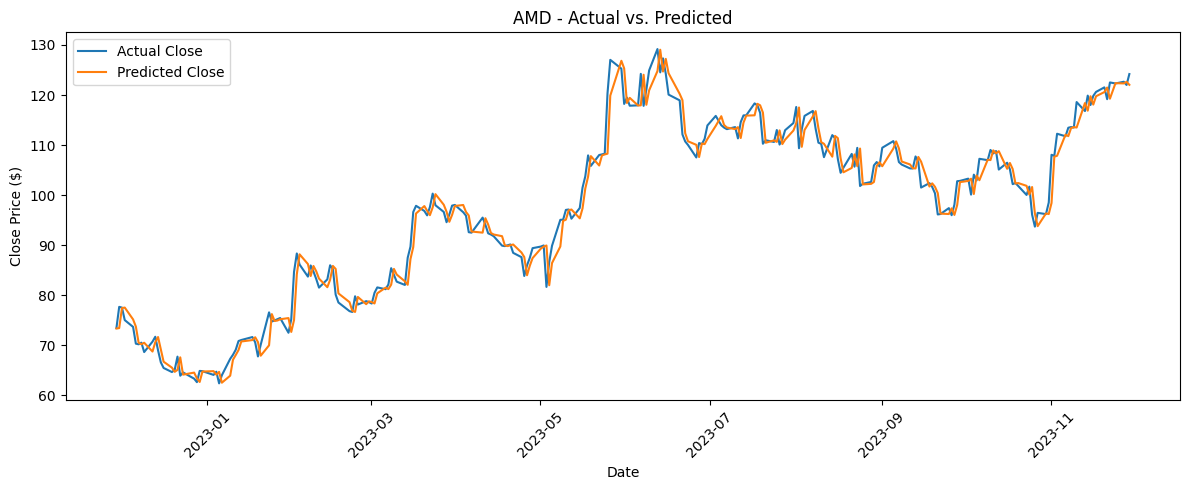

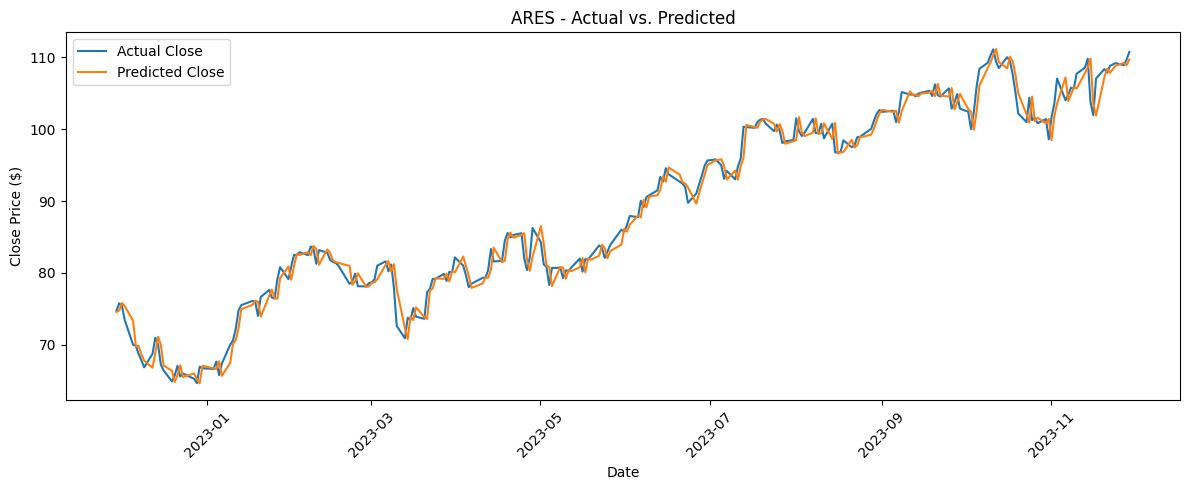

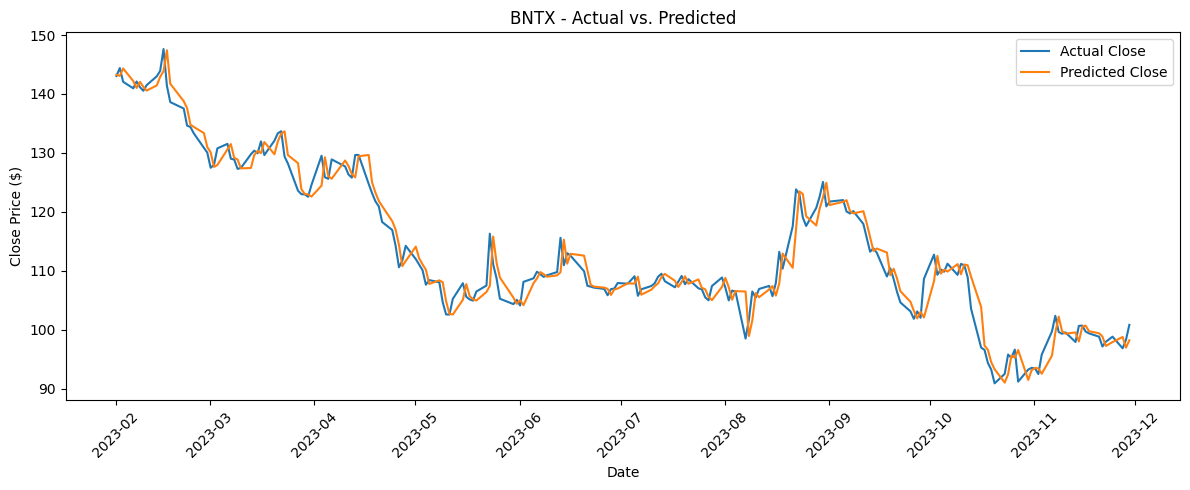

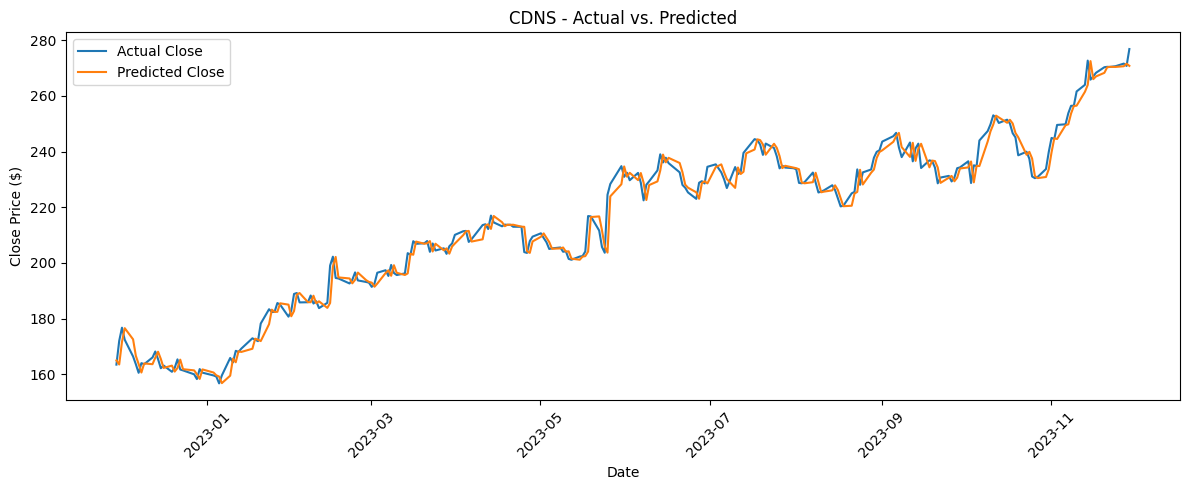

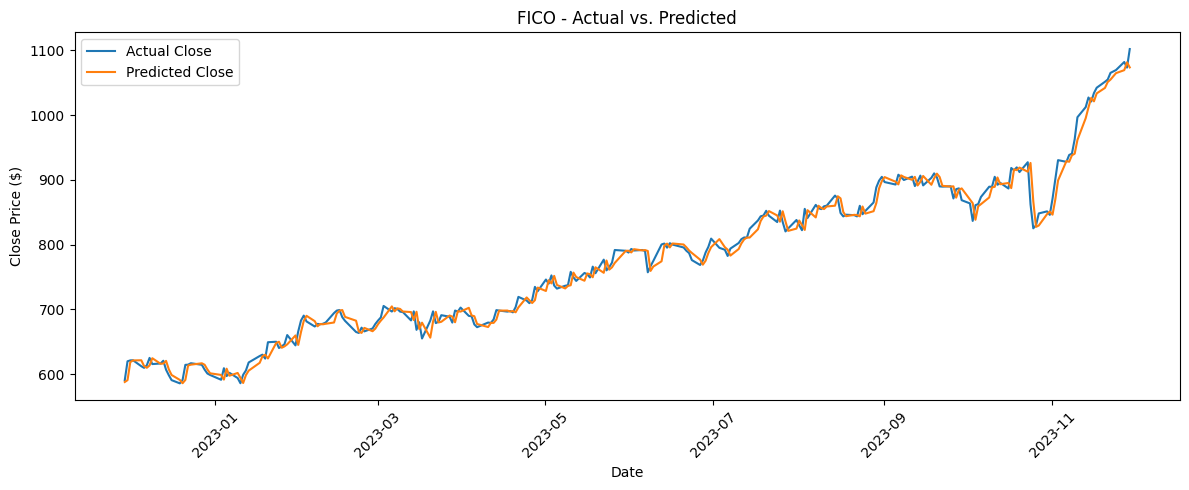

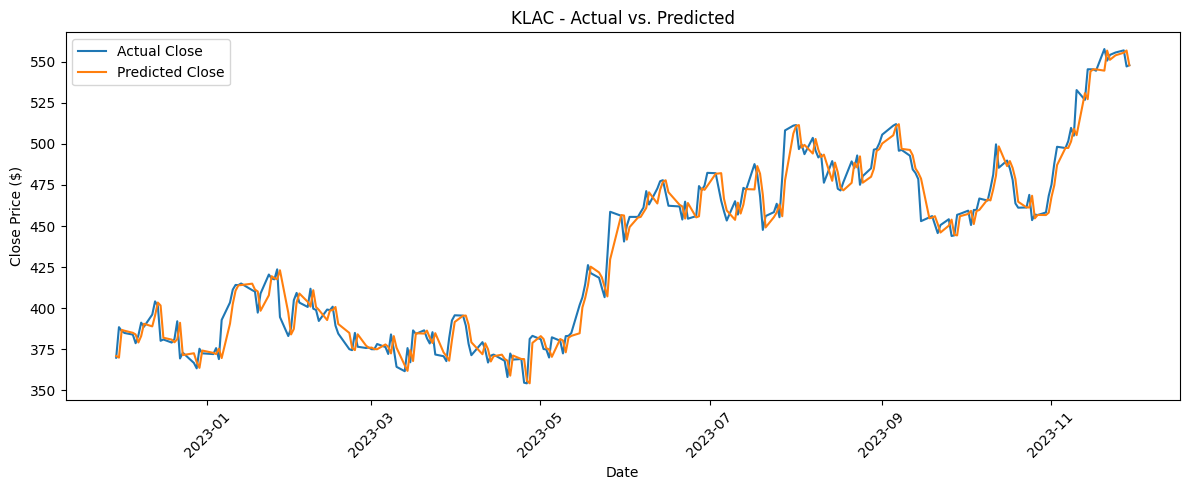

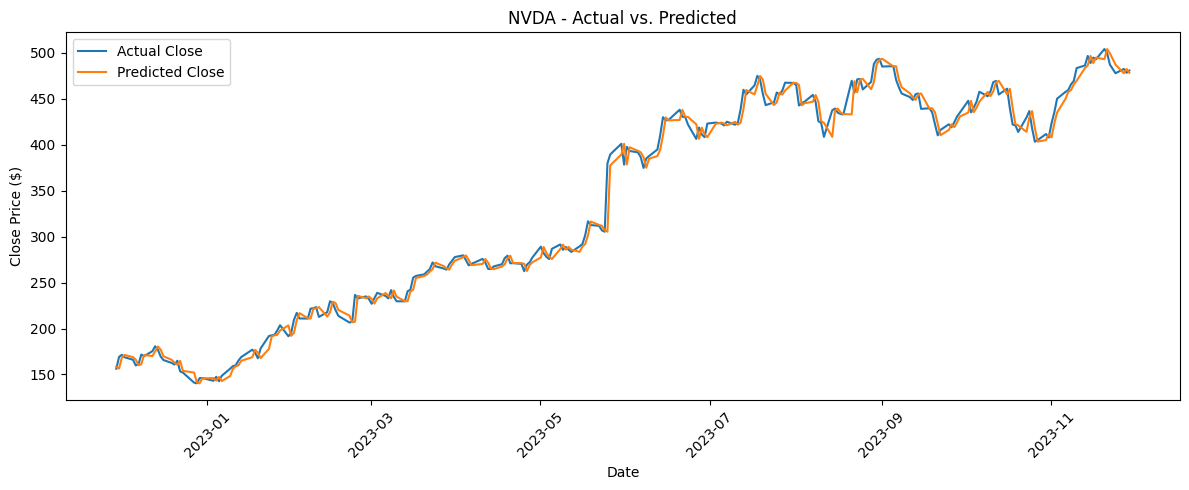

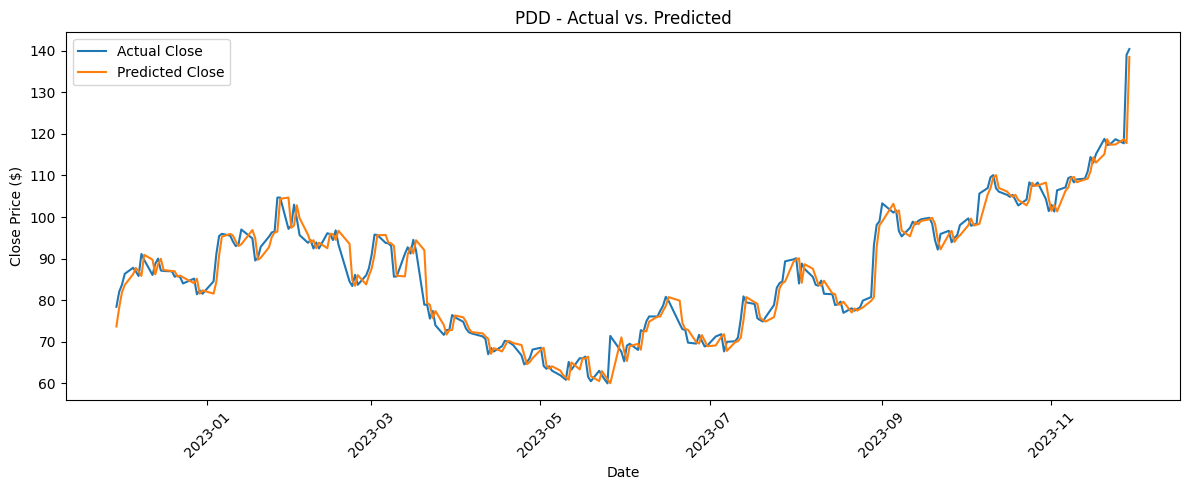

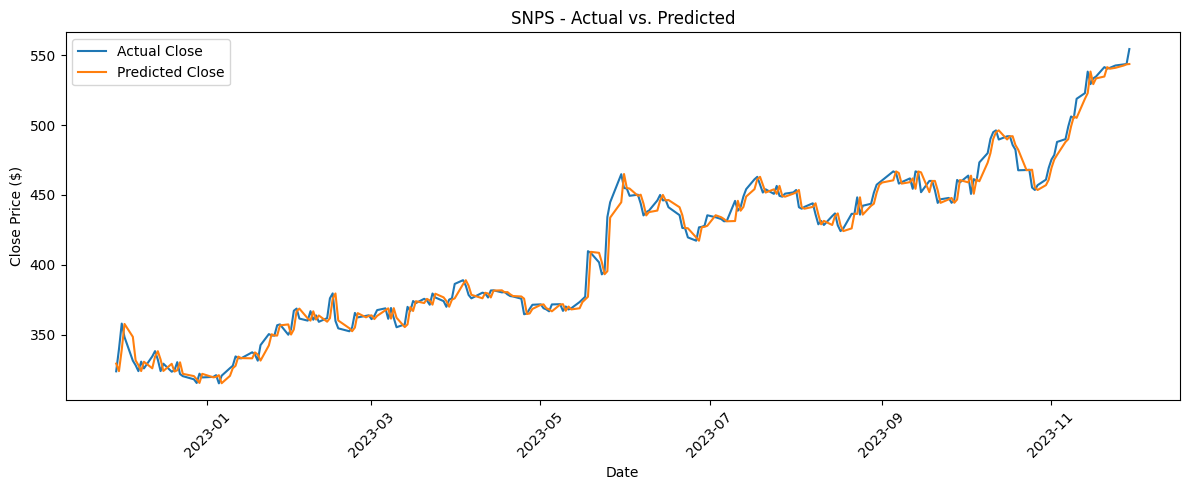

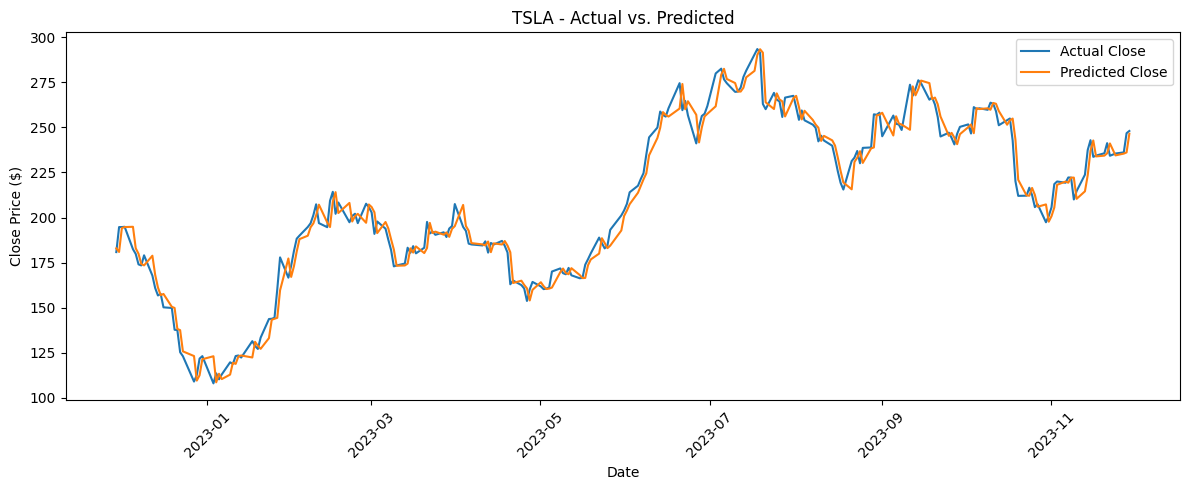

In [170]:


gainer_stocks = predictions_allstocks_df[predictions_allstocks_df["Company"].isin(gainers_companies.tolist())]

for company, data in gainer_stocks.groupby("Company"):
    data = data.sort_values("Date")

    plt.figure(figsize=(12, 5))
    plt.plot(data["Date"], data["Actual_Close"], label="Actual Close")
    plt.plot(data["Date"], data["ARIMA_Predicted"], label="Predicted Close")

    plt.title(f"{company} - Actual vs. Predicted")
    plt.xlabel("Date")
    plt.ylabel("Close Price ($)")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


#### **Top 10 Lossers: Actual vs. Predicted**

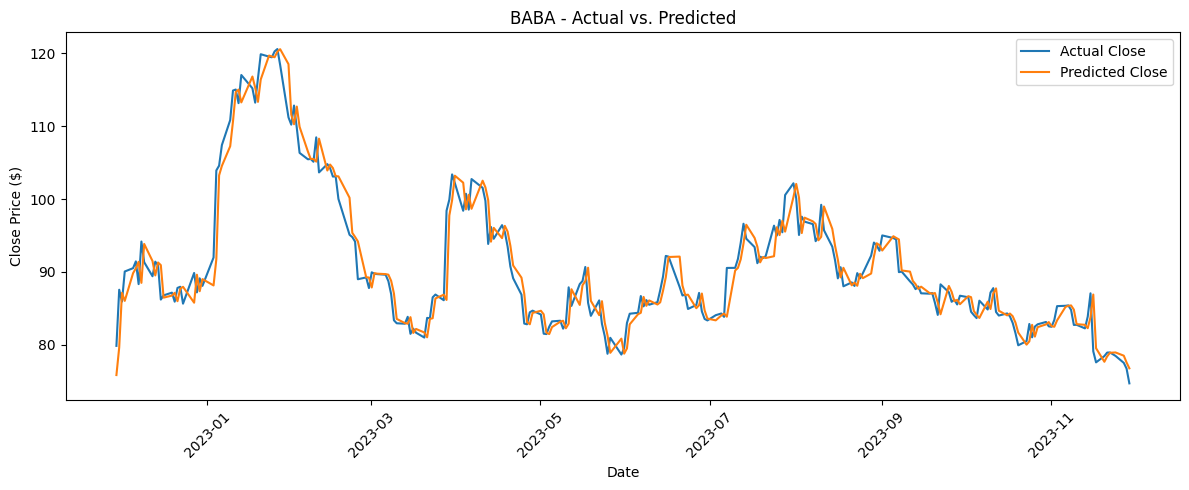

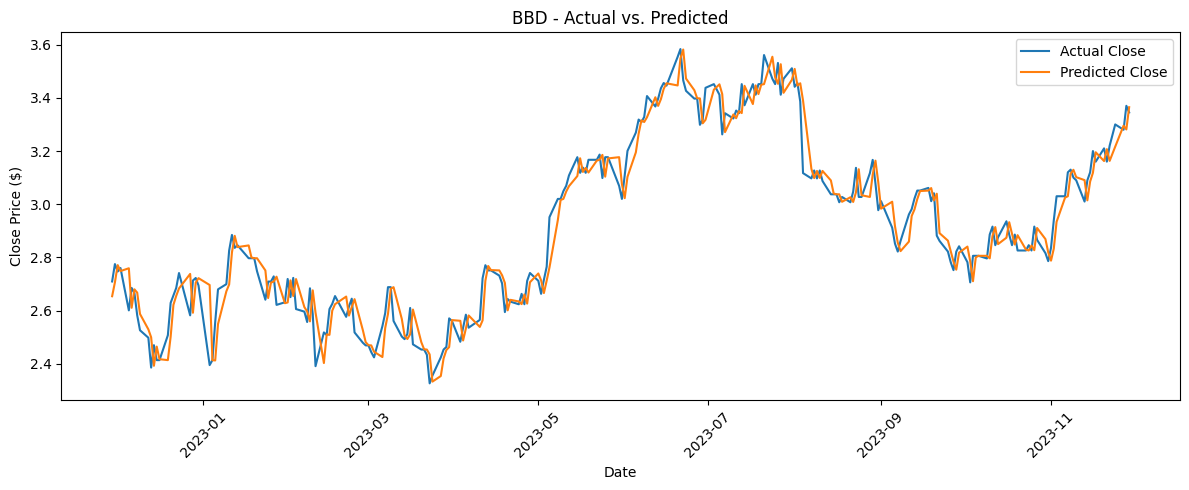

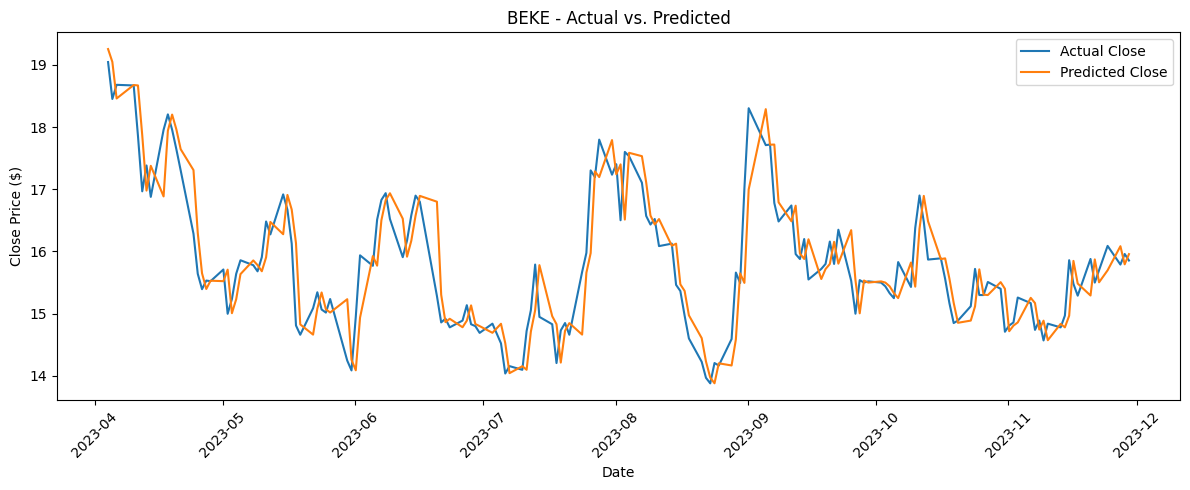

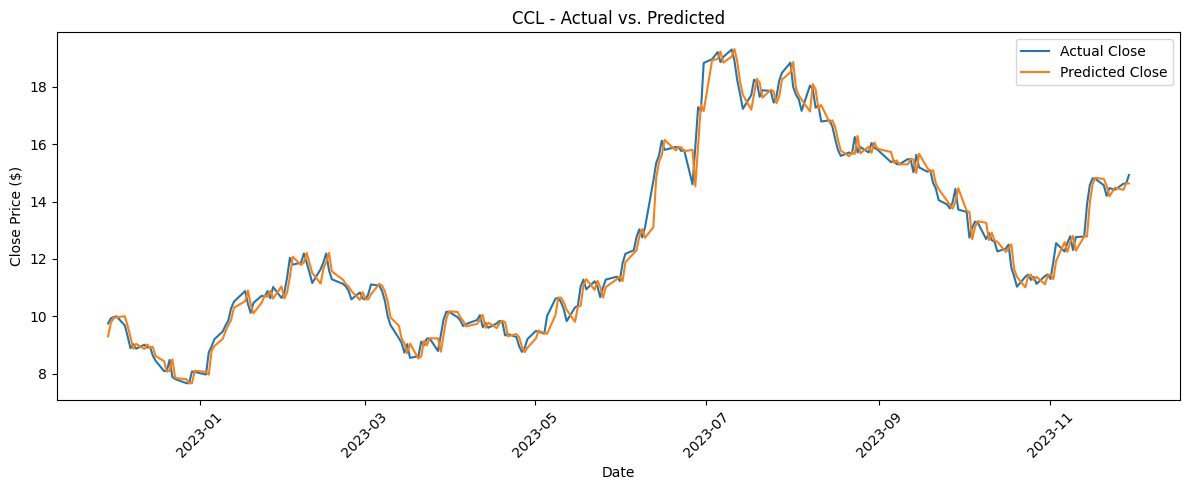

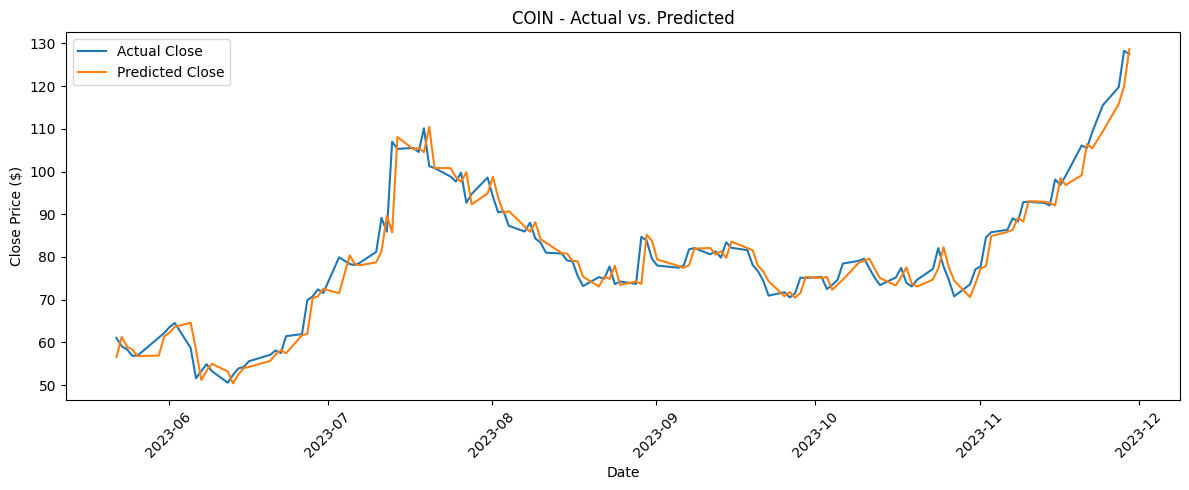

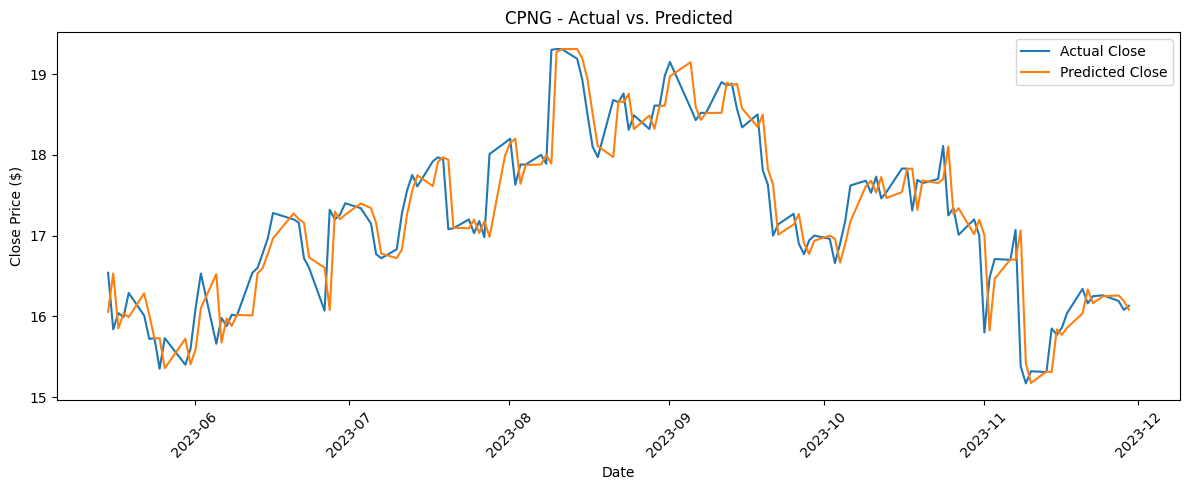

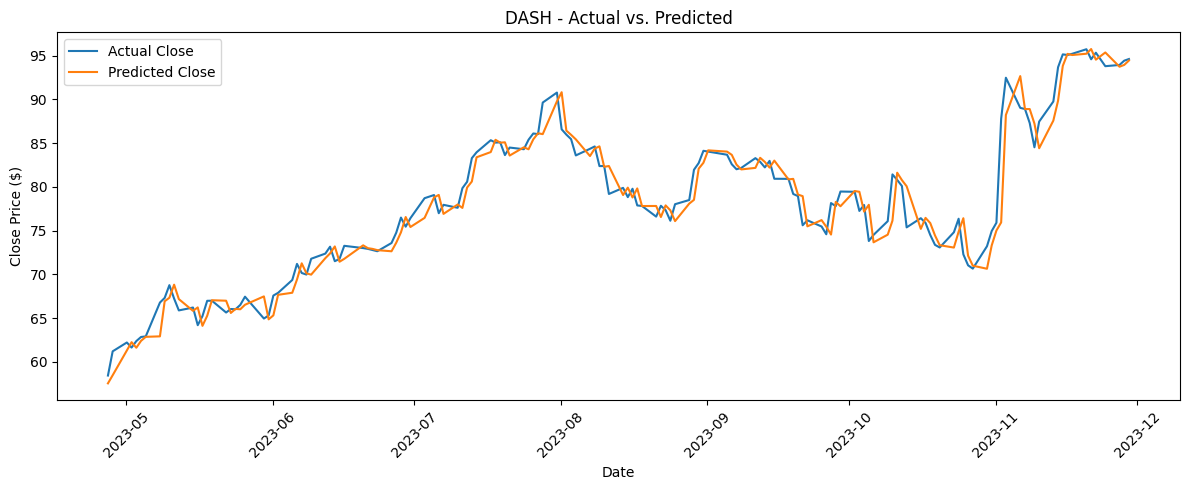

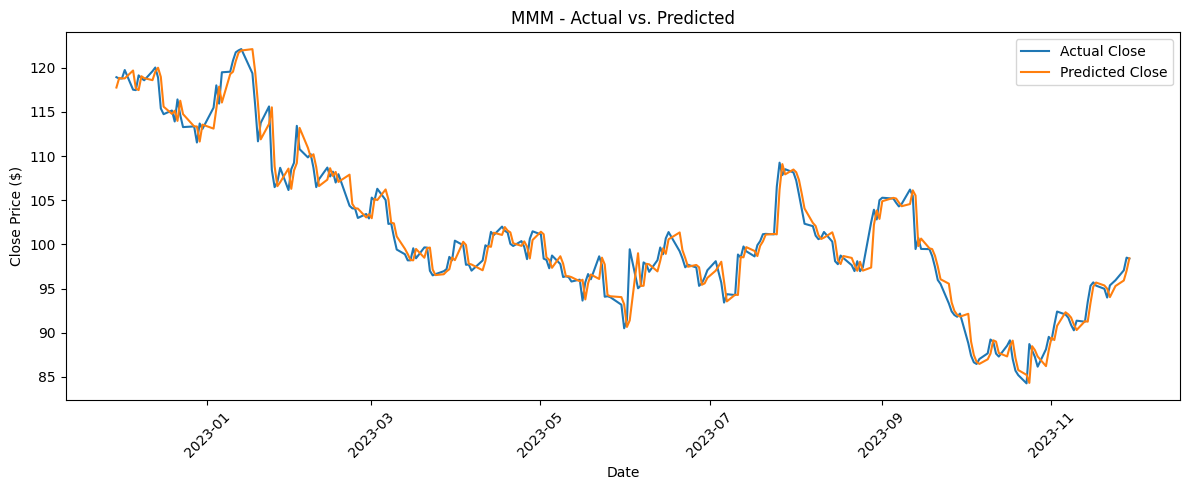

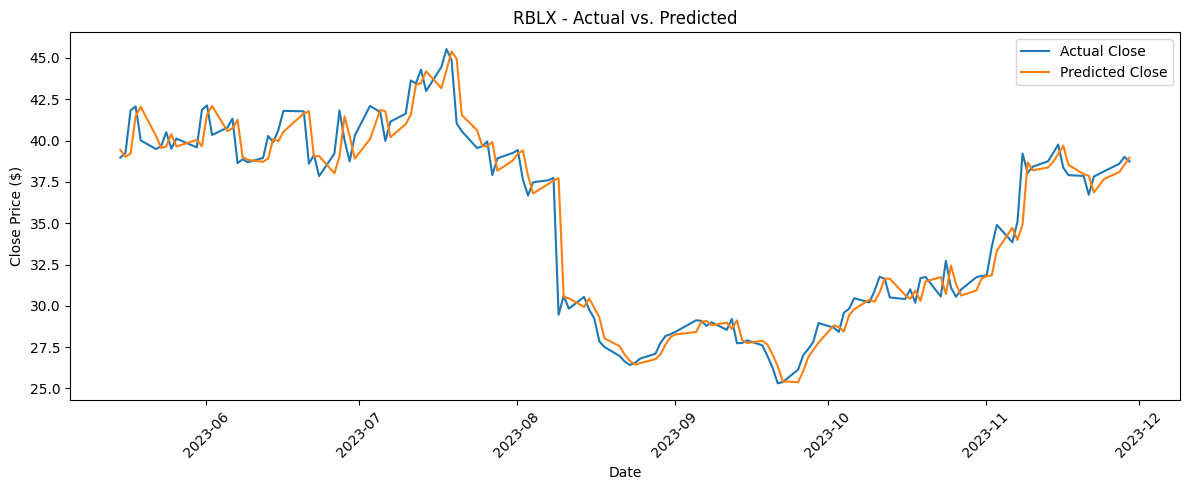

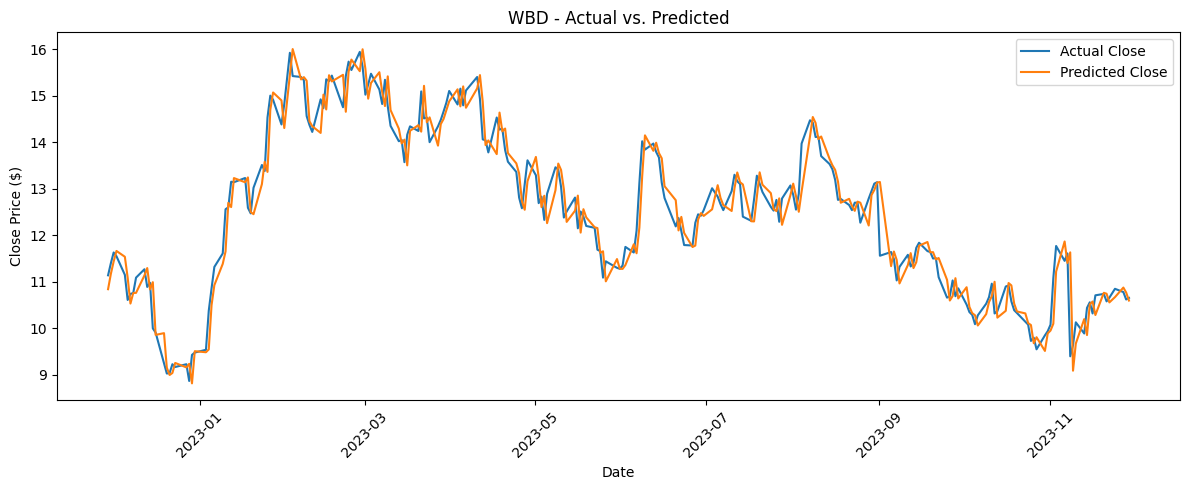

In [171]:


losser_stocks = predictions_allstocks_df[predictions_allstocks_df["Company"].isin(lossers_companies.tolist())]

for company, data in losser_stocks.groupby("Company"):
    data = data.sort_values("Date")

    company_df = df[df["Company"] == company].sort_values("Date")



    plt.figure(figsize=(12, 5))
    plt.plot(data["Date"], data["Actual_Close"], label="Actual Close")
    plt.plot(data["Date"], data["ARIMA_Predicted"], label="Predicted Close")

    plt.title(f"{company} - Actual vs. Predicted")
    plt.xlabel("Date")
    plt.ylabel("Close Price ($)")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

#### **Model Performance Metrics**

In [172]:
# Display the MAE and MASE metrics for all stocks, sorted by MASE in ascending order
print(metrics_allstocks_df[["Company", "ARIMA_MAE", "Baseline_MAE", "MASE"]].sort_values("MASE"))

# Median MASE
print("Median MASE:", metrics_allstocks_df["MASE"].median())

# Mean MASE
print("Mean MASE:", metrics_allstocks_df["MASE"].mean())

# If Arima beats the baseline
print("Amount ARIMA better: ", metrics_allstocks_df["ARIMA_beats_Baseline"].mean() * 100, " %")

    Company  ARIMA_MAE  Baseline_MAE      MASE
488      ZM   1.260408      1.260043  0.217038
394    SNAP   0.256822      0.254212  0.285509
54     BEKE   0.389574      0.389846  0.314423
126    DASH   1.333515      1.335400  0.340393
67     BNTX   1.876212      1.865646  0.349986
..      ...        ...           ...       ...
348     PKX   1.810850      1.796032  2.059694
320    NVDA   7.118789      7.083472  2.175383
261     LLY   5.437617      5.455457  2.190253
321     NVO   1.049111      1.044089  2.285795
413     SYM   2.207051      2.175290  6.410820

[491 rows x 4 columns]
Median MASE: 0.9810293090210738
Mean MASE: 1.0085345410761164
Amount ARIMA better:  29.327902240325866  %


#### **Conclusion: ARIMA Performance Across 491 Stocks**

ARIMA outperformed the naive baseline for only 29.33% of the 491 stocks. The median MASE was 0.98, while the mean MASE was 1.01.

Overall, ARIMA did not consistently outperform the baseline, showing that its forecasting performance varies across stocks.

#### **META: Actual vs. Predicted**

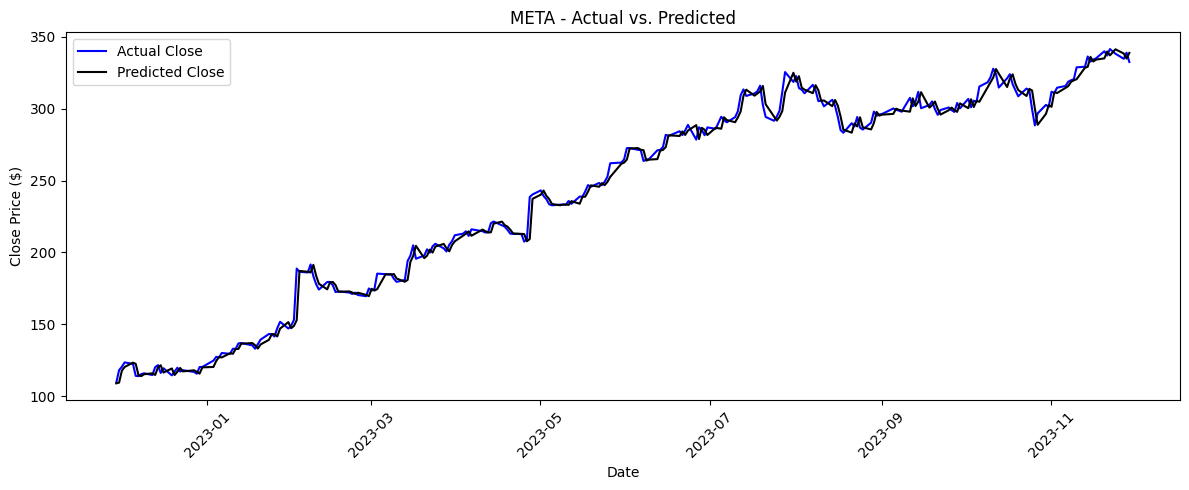

In [173]:
# Actual vs. Predicted Close values

plt.figure(figsize=(12, 5))

plt.plot(
    predictions_meta_df["Date"],
    predictions_meta_df["Actual_Close"],
    label="Actual Close",
    color="blue"
)

plt.plot(
    predictions_meta_df["Date"],
    predictions_meta_df["ARIMA_Predicted"],
    label="Predicted Close",
    color="black"
)

plt.title("META - Actual vs. Predicted")
plt.xlabel("Date")
plt.ylabel("Close Price ($)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### **Model Performance Metrics**

In [174]:
# Display the MAE and MASE metrics for META, sorted by MASE in ascending order
print(metrics_meta_df[["Company", "ARIMA_MAE", "Baseline_MAE", "MASE"]].sort_values("MASE"))

# Median MASE
print("Median MASE:", metrics_meta_df["MASE"].median())

#Median MASE
print("Mean MASE:", metrics_meta_df["MASE"].mean())

# If Arima beats the baseline
print("ARIMA better: ", metrics_meta_df["ARIMA_beats_Baseline"].mean() * 100, " %")

  Company  ARIMA_MAE  Baseline_MAE      MASE
0    META   3.904816      3.910436  0.959262
Median MASE: 0.9592616950229309
Mean MASE: 0.9592616950229309
ARIMA better:  100.0  %


##### **Conclusion: ARIMA Performance on META Stock with Optimized Parameters**

For Meta, ARIMA achieved a slightly lower MAE (3.90) than the naive baseline (3.91). The MASE was 0.96, indicating that ARIMA performed slightly better than the baseline in this evaluation. However, the improvement was very small.